Found 17471 images belonging to 2 classes.
Found 3743 images belonging to 2 classes.
Classes: {'Cat': 0, 'Dog': 1}


c:\tfenv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 813,217 (3.10 MB)

 Trainable params: 813,217 (3.10 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
546/546 ━━━━━━━━━━━━━━━━━━━━ 155s 278ms/step - accuracy: 0.6367 - loss: 0.6342 - val_accuracy: 0.7021 - val_loss: 0.5705
Epoch 2/15
546/546 ━━━━━━━━━━━━━━━━━━━━ 102s 186ms/step - accuracy: 0.7244 - loss: 0.5456 - val_accuracy: 0.7392 - val_loss: 0.5287
Epoch 3/15
546/546 ━━━━━━━━━━━━━━━━━━━━ 88s 161ms/step - accuracy: 0.7518 - loss: 0.5060 - val_accuracy: 0.7700 - val_loss: 0.4767
Epoch 4/15
546/546 ━━━━━━━━━━━━━━━━━━━━ 102s 188ms/step - accuracy: 0.7737 - loss: 0.4724 - val_accuracy: 0.7686 - val_loss: 0.4759
Epoch 5/15
546/546 ━━━━━━━━━━━━━━━━━━━━ 109s 200ms/step - accuracy: 0.7843 - loss: 0.4537 - val_accuracy: 0.7895 - val_loss: 0.4501
Epoch 6/15
546/546 ━━━━━━━━━━━━━━━━━━━━ 113s 207ms/step - accuracy: 0.7966 - loss: 0.4358 - val_accuracy: 0.7812 - val_loss: 0.4632
Epoch 7/15
546/546 ━━━━━━━━━━━━━━━━━━━━ 102s 186ms/step - accuracy: 0.8090 - loss: 0.4143 - val_accuracy: 0.8031 - val_loss: 0.4457
Epoch 8/15
546/546 ━━━━━━━━━━━━━━━━━━━━ 102s 187ms/step - accuracy: 0.8216 - 

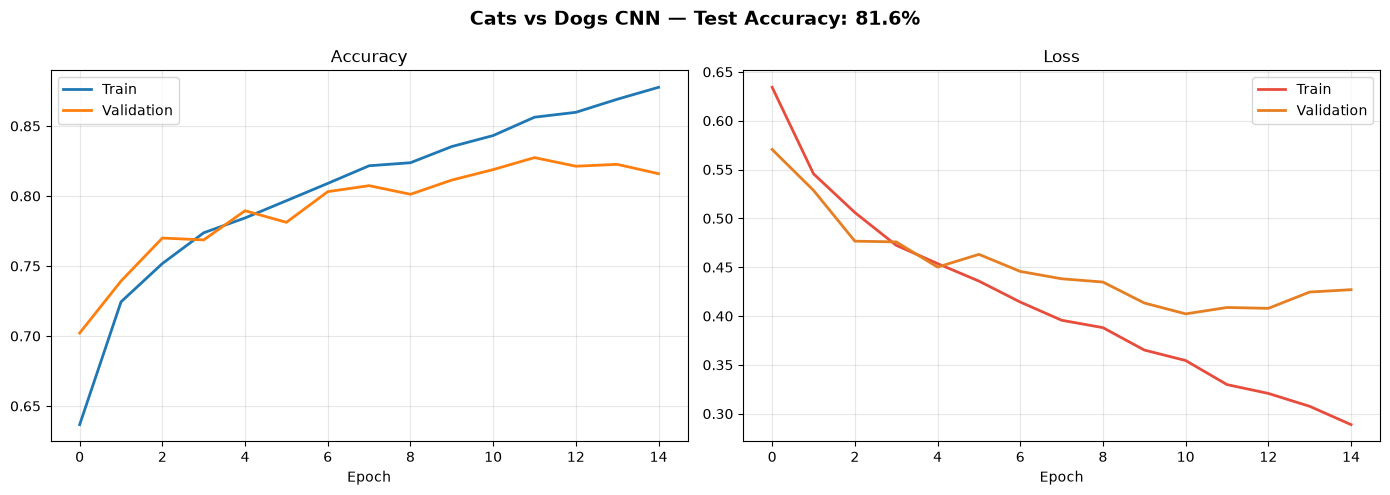

In [1]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPool2D, Flatten, Dense
import matplotlib.pyplot as plt

# --- Paths ---
TRAIN_PATH = r"C:\Users\HP\Downloads\cats_and_dogs\dataset\training_set"
TEST_PATH  = r"C:\Users\HP\Downloads\cats_and_dogs\dataset\test_set"

IMG_SIZE = (64, 64)

# --- Data Generators ---
train_datagen = ImageDataGenerator(rescale=1./255, shear_range=0.2,
                                   zoom_range=0.2, horizontal_flip=True)
test_datagen = ImageDataGenerator(rescale=1./255)

train_set = train_datagen.flow_from_directory(TRAIN_PATH, target_size=IMG_SIZE,
                                              batch_size=32, class_mode='binary')
test_set = test_datagen.flow_from_directory(TEST_PATH, target_size=IMG_SIZE,
                                            batch_size=32, class_mode='binary', shuffle=False)

print("Classes:", train_set.class_indices)

# --- Build CNN ---
model = Sequential([
    Conv2D(32, 3, activation='relu', input_shape=[64, 64, 3]),
    MaxPool2D(2, 2),
    Conv2D(32, 3, activation='relu'),
    MaxPool2D(2, 2),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

# --- Train ---
history = model.fit(train_set, validation_data=test_set, epochs=15)

# --- Evaluate ---
test_loss, test_acc = model.evaluate(test_set, verbose=0)
print(f"\nTest Accuracy: {test_acc:.1%}")

# --- Training Curves ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history.history['accuracy'], label='Train', linewidth=2)
ax1.plot(history.history['val_accuracy'], label='Validation', linewidth=2)
ax1.set_title('Accuracy')
ax1.set_xlabel('Epoch')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(history.history['loss'], label='Train', linewidth=2, color='#e74c3c')
ax2.plot(history.history['val_loss'], label='Validation', linewidth=2, color='#e67e22')
ax2.set_title('Loss')
ax2.set_xlabel('Epoch')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.suptitle(f'Cats vs Dogs CNN — Test Accuracy: {test_acc:.1%}', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()